# 6D. Time Series Analysis: Holt-Winters (ETS) & SARIMA (RQ3)

Keputusan (lihat `docs/analysis_plan.md` bagian 9, Draft):
- Deret: **kota keseluruhan** dan **Top-5 zona**. Top-5 dipilih dari total pickup **training (Jan-Apr) saja**.
- Periode musiman **24 jam** (deret per jam).
- Split kronologis: Train Jan-Apr, Validation Mei, Test Juni (**dipakai sekali**, lihat `RUN_TEST`).
- Evaluasi **1 jam ke depan (one-step-ahead)** dengan parameter tetap dari training dan state yang diperbarui dengan data aktual. Ini setara horizon baseline Seasonal Naive (lag 168) dan model fitur.
- Metrik: MAE, RMSE, WAPE, MASE (utama) dari `script/tools/metrics.py`. MASE memakai pembagi **per deret**: rata-rata |aktual - lag168| pada training deret itu.
- Jam DST 2026-03-08 02:00 bernilai NaN; untuk fitting diisi interpolasi linear (hanya di training), dan dicatat sebagai keputusan.

## 0. Import & Konfigurasi

In [1]:
import gc, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

sys.path.append("tools")
import metrics as mt

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
M_PER = 24                       # periode musiman (jam)
K_TOP = 5
T_VAL = pd.Timestamp("2026-05-01")
T_TEST = pd.Timestamp("2026-06-01")
RUN_TEST = False                 # True hanya setelah model final diumumkan Anggota 4
FINAL_MODEL = None               # contoh: ("city", "SARIMA")
TUNE = False                     # True untuk menjalankan grid tuning (Fase 7, lambat)

GRID = "../datasets/interim/2026/demand_zone_hour.parquet"
RIO_TOP5 = "../datasets/interim/2026/timeseries_top5.parquet"
OUT = "../out/output_eda"
os.makedirs(OUT, exist_ok=True)

## 1. Muat Deret & Pilih Top-5 dari Training
`timeseries_top5.parquet` dari Fase 5 dihitung dari total Jan-Jun (bocor). Di sini dihitung ulang dari training saja.

In [2]:
grid = pd.read_parquet(GRID, columns=["hour", "zone_id", "PU_zone_name", "pickup_count"])

train_tot = (grid[grid["hour"] < T_VAL].groupby(["zone_id", "PU_zone_name"])["pickup_count"].sum()
             .nlargest(K_TOP).reset_index())
print("Top-5 (training saja):")
print(train_tot.to_string(index=False))

if os.path.exists(RIO_TOP5):
    rio = pd.read_parquet(RIO_TOP5)["zone_id"].unique()
    print("\nTop-5 file Fase 5 (Jan-Jun):", sorted(rio), "| sama dengan training-only:",
          set(rio) == set(train_tot["zone_id"]))

series = {"city": grid.groupby("hour")["pickup_count"].sum(min_count=1)}
for zid, nama in train_tot[["zone_id", "PU_zone_name"]].itertuples(index=False):
    series[f"z{zid} {nama}"] = grid[grid["zone_id"] == zid].set_index("hour")["pickup_count"]
series = {k: v.sort_index().asfreq("h") for k, v in series.items()}

dst = pd.Timestamp("2026-03-08 02:00")
for k, v in series.items():
    print(f"{k:35s} n={len(v)}  NaN={int(v.isna().sum())}  min={v.min():.0f}  max={v.max():.0f}")

Top-5 (training saja):
 zone_id          PU_zone_name  pickup_count
     237 Upper East Side South      644075.0
     161        Midtown Center      595133.0
     236 Upper East Side North      593692.0
     132           JFK Airport      531353.0
     162          Midtown East      436548.0

Top-5 file Fase 5 (Jan-Jun): [np.int64(132), np.int64(161), np.int64(162), np.int64(236), np.int64(237)] | sama dengan training-only: True
city                                n=4344  NaN=1  min=110  max=12320
z237 Upper East Side South          n=4344  NaN=1  min=0  max=757
z161 Midtown Center                 n=4344  NaN=1  min=0  max=826
z236 Upper East Side North          n=4344  NaN=1  min=0  max=670
z132 JFK Airport                    n=4344  NaN=1  min=0  max=573
z162 Midtown East                   n=4344  NaN=1  min=0  max=575


## 2. Split & Penanganan DST

In [3]:
data = {}
for k, v in series.items():
    s = v.copy()
    dst_mask = s.index == dst
    s_fit = s.interpolate(method="linear", limit_direction="both")   # hanya mengisi jam DST (training)
    assert s.loc[T_VAL:].isna().sum() == 0, "NaN di validation/test"
    data[k] = {"y": s_fit, "dst_mask": dst_mask,
               "train": s_fit[s_fit.index < T_VAL],
               "val": s_fit[(s_fit.index >= T_VAL) & (s_fit.index < T_TEST)],
               "test": s_fit[s_fit.index >= T_TEST]}
d = data["city"]
print("city  train/val/test:", len(d["train"]), len(d["val"]), len(d["test"]))

city  train/val/test: 2880 744 720


## 3. Eksplorasi: Plot Deret & Dekomposisi MSTL (24 jam dan 168 jam)

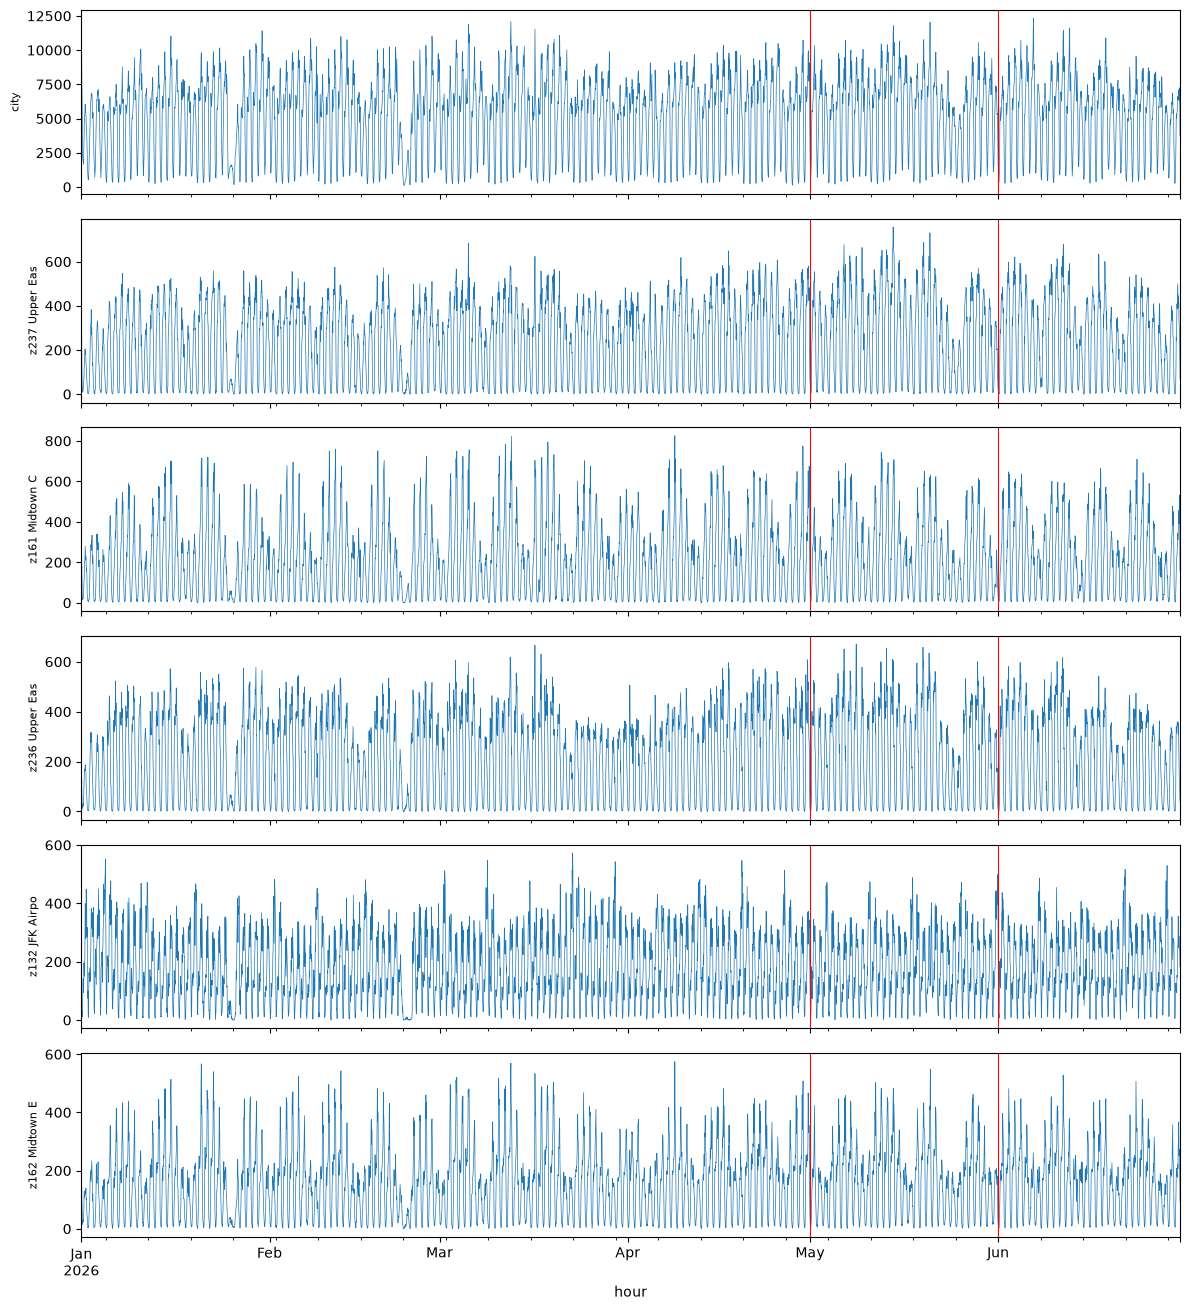

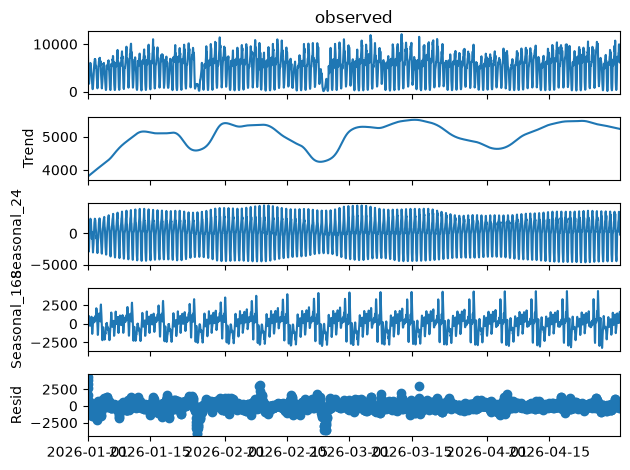

Proporsi varians per komponen musiman (city): {'seasonal_24': 0.718, 'seasonal_168': 0.198}


In [4]:
fig, ax = plt.subplots(len(data), 1, figsize=(12, 2.2 * len(data)), sharex=True)
for a, (k, d) in zip(ax, data.items()):
    d["y"].plot(ax=a, lw=0.5); a.set_ylabel(k[:14], fontsize=8)
    a.axvline(T_VAL, color="r", lw=0.8); a.axvline(T_TEST, color="r", lw=0.8)
plt.tight_layout(); plt.savefig(f"{OUT}/08_ts_series.png", dpi=130); plt.show()

res_mstl = MSTL(data["city"]["train"], periods=[24, 168]).fit()
res_mstl.plot(); plt.savefig(f"{OUT}/08_ts_mstl_city.png", dpi=130); plt.show()
var_share = {c: float(res_mstl.seasonal[c].var() / data["city"]["train"].var()) for c in res_mstl.seasonal.columns}
print("Proporsi varians per komponen musiman (city):", {k: round(v, 3) for k, v in var_share.items()})

## 4. Stasioneritas (ADF), Differencing, ACF/PACF

In [5]:
rows = []
for k, d in data.items():
    y = d["train"]
    for nama, z in [("level", y), ("diff24", y.diff(24).dropna()), ("diff1+diff24", y.diff(24).diff(1).dropna())]:
        stat, p, *_ = adfuller(z, autolag="AIC")
        rows.append({"deret": k, "transformasi": nama, "ADF": stat, "p_value": p, "stasioner(p<0.05)": p < 0.05})
adf_tbl = pd.DataFrame(rows)
adf_tbl.to_csv(f"{OUT}/08_ts_adf.csv", index=False)
adf_tbl.round(4)

,deret,transformasi,ADF,p_value,stasioner(p<0.05)
0,city,level,-6.2350,0.0,True
1,city,diff24,-9.4773,0.0,True
2,city,diff1+diff24,-15.0272,0.0,True
3,z237 Upper East Side South,level,-5.9889,0.0,True
4,z237 Upper East Side South,diff24,-7.7190,0.0,True
5,z237 Upper East Side South,diff1+diff24,-15.9198,0.0,True
6,z161 Midtown Center,level,-5.4777,0.0,True
7,z161 Midtown Center,diff24,-7.7800,0.0,True
8,z161 Midtown Center,diff1+diff24,-15.0630,0.0,True
9,z236 Upper East Side North,level,-5.9256,0.0,True


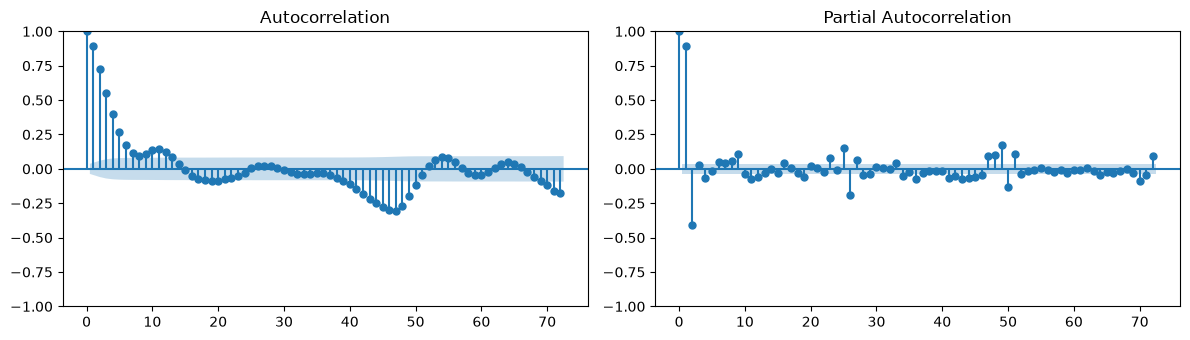

In [6]:
y = data["city"]["train"].diff(24).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(y, lags=72, ax=ax[0]); plot_pacf(y, lags=72, ax=ax[1], method="ywm")
plt.tight_layout(); plt.savefig(f"{OUT}/08_ts_acf_pacf_city.png", dpi=130); plt.show()

## 5. Baseline Seasonal Naive (lag 168) per Deret
Pembagi MASE per deret dari training. Baseline memakai nilai aktual 168 jam sebelumnya.

In [7]:
def pred_naive168(y_all, idx):
    return y_all.shift(168).loc[idx]

scales = {}
for k, d in data.items():
    tr = d["train"]
    scales[k] = mt.mase_scale(tr.iloc[168:], tr.shift(168).iloc[168:])
    print(f"{k:35s} MASE scale = {scales[k]:.3f}")

city                                MASE scale = 690.963
z237 Upper East Side South          MASE scale = 40.591
z161 Midtown Center                 MASE scale = 41.150
z236 Upper East Side North          MASE scale = 40.884
z132 JFK Airport                    MASE scale = 49.708
z162 Midtown East                   MASE scale = 29.888


## 6. Model: Holt-Winters (ETS) dan SARIMA, evaluasi one-step-ahead
Fit pada training, lalu `smooth` dengan parameter tetap pada seluruh deret; `fittedvalues` pada periode evaluasi = prediksi 1 jam ke depan.
Waktu training dan waktu prediksi dicatat untuk tabel trade-off (Fase 7).

In [8]:
def fit_ets(y_train, y_all, trend=None, damped=False, seasonal="add"):
    if seasonal == "mul" and y_train.min() <= 0:
        return None
    t0 = time.perf_counter()
    mod = ETSModel(y_train, error="add", trend=trend, damped_trend=damped,
                   seasonal=seasonal, seasonal_periods=M_PER)
    r = mod.fit(disp=False, maxiter=200)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    sm = ETSModel(y_all, error="add", trend=trend, damped_trend=damped,
                  seasonal=seasonal, seasonal_periods=M_PER).smooth(r.params)
    pred = sm.fittedvalues.copy()
    t_pred = time.perf_counter() - t0
    aic = float(r.aic)
    del sm, r
    gc.collect()
    return {"pred": pred, "fit_s": t_fit, "pred_s": t_pred, "aic": aic}

def fit_sarima(y_train, y_all, order=(1, 0, 1), sorder=(1, 1, 1, M_PER)):
    t0 = time.perf_counter()
    r = SARIMAX(y_train, order=order, seasonal_order=sorder).fit(disp=False, maxiter=100)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    sm = SARIMAX(y_all, order=order, seasonal_order=sorder).smooth(r.params)
    pred = sm.fittedvalues.copy()
    t_pred = time.perf_counter() - t0
    aic = float(r.aic)
    del sm, r
    gc.collect()
    return {"pred": pred, "fit_s": t_fit, "pred_s": t_pred, "aic": aic}

def score(k, nama, pred, idx, extra=None):
    y_true = data[k]["y"].loc[idx]
    m = mt.regression_metrics(y_true, pred.loc[idx], scale=scales[k])
    return {"deret": k, "model": nama, **m, **(extra or {})}

In [9]:
rows, fitted = [], {}
for k, d in data.items():
    y_all, idx = d["y"], d["val"].index
    rows.append(score(k, "SeasonalNaive168", pred_naive168(y_all, idx), idx, {"fit_s": 0.0, "pred_s": 0.0}))
    for nama, fn in [("HW-ETS (A,N,A)", lambda: fit_ets(d["train"], y_all, None, False, "add")),
                     ("SARIMA (1,0,1)(1,1,1,24)", lambda: fit_sarima(d["train"], y_all))]:
        out = fn()
        if out is None:
            continue
        fitted[(k, nama)] = out
        rows.append(score(k, nama, out["pred"], idx, {"fit_s": out["fit_s"], "pred_s": out["pred_s"], "aic": out["aic"]}))
    print("selesai:", k)
val_tbl = pd.DataFrame(rows)
val_tbl.to_csv(f"{OUT}/08_ts_metrics_validation.csv", index=False)
val_tbl.round(4)

selesai: city
selesai: z237 Upper East Side South
selesai: z161 Midtown Center
selesai: z236 Upper East Side North
selesai: z132 JFK Airport
selesai: z162 Midtown East


,deret,model,mae,rmse,wape,r2,mase,fit_s,pred_s,aic
0,city,SeasonalNaive168,806.4288,1153.7025,0.1500,0.8359,1.1671,0.0000,0.0000,NaN
1,city,"HW-ETS (A,N,A)",952.8597,1378.4181,0.1773,0.7658,1.3790,0.7605,0.8563,50732.3526
2,city,"SARIMA (1,0,1)(1,1,1,24)",410.7729,585.4257,0.0764,0.9578,0.5945,20.0003,5.2546,44340.7608
3,z237 Upper East Side South,SeasonalNaive168,54.4019,83.5984,0.2094,0.8242,1.3402,0.0000,0.0000,NaN
4,z237 Upper East Side South,"HW-ETS (A,N,A)",34.1555,48.4359,0.1315,0.9410,0.8415,2.8157,0.6521,29608.8817
5,z237 Upper East Side South,"SARIMA (1,0,1)(1,1,1,24)",31.3437,44.2650,0.1206,0.9507,0.7722,13.5418,4.6582,28939.2485
6,z161 Midtown Center,SeasonalNaive168,38.7675,63.3202,0.1829,0.8751,0.9421,0.0000,0.0000,NaN
7,z161 Midtown Center,"HW-ETS (A,N,A)",57.2161,82.9198,0.2699,0.7859,1.3904,0.5581,0.6552,34301.5091
8,z161 Midtown Center,"SARIMA (1,0,1)(1,1,1,24)",27.0779,39.6993,0.1277,0.9509,0.6580,14.1634,5.0490,29704.4995
9,z236 Upper East Side North,SeasonalNaive168,43.8750,69.5939,0.1905,0.8551,1.0732,0.0000,0.0000,NaN


## 7. Aktual vs Prediksi (Validation, 14 hari terakhir Mei) dan Cek Residual

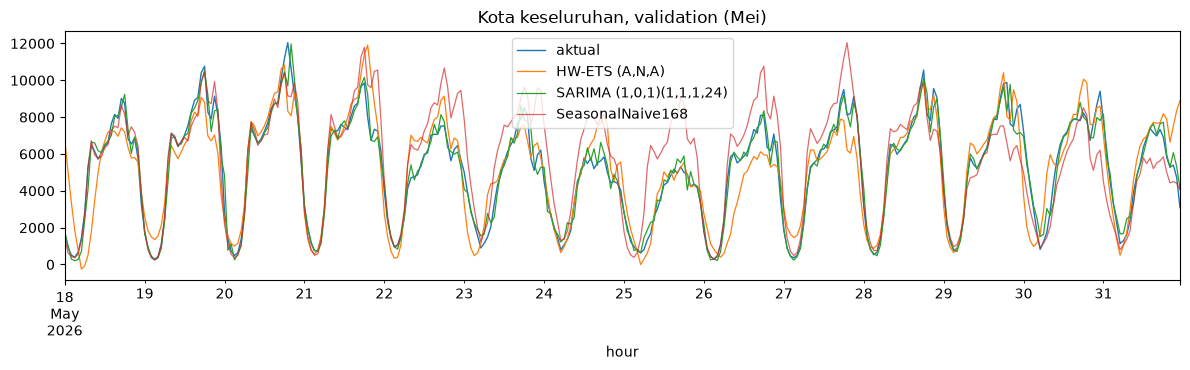

,deret,model,Ljung-Box lag24 p,mean_resid
0,city,"HW-ETS (A,N,A)",0.0,3.9538
1,city,"SARIMA (1,0,1)(1,1,1,24)",0.0,30.8262
2,z237 Upper East Side South,"HW-ETS (A,N,A)",0.0,0.0429
3,z237 Upper East Side South,"SARIMA (1,0,1)(1,1,1,24)",0.0,1.6355
4,z161 Midtown Center,"HW-ETS (A,N,A)",0.0,0.2855
5,z161 Midtown Center,"SARIMA (1,0,1)(1,1,1,24)",0.0,1.2288
6,z236 Upper East Side North,"HW-ETS (A,N,A)",0.0,-0.0073
7,z236 Upper East Side North,"SARIMA (1,0,1)(1,1,1,24)",0.0,1.2665
8,z132 JFK Airport,"HW-ETS (A,N,A)",0.0,-0.0355
9,z132 JFK Airport,"SARIMA (1,0,1)(1,1,1,24)",0.0,-0.2966


In [10]:
k = "city"
idx = data[k]["val"].index[-24 * 14:]
fig, a = plt.subplots(figsize=(12, 3.8))
data[k]["y"].loc[idx].plot(ax=a, label="aktual", lw=1)
for nama in ["HW-ETS (A,N,A)", "SARIMA (1,0,1)(1,1,1,24)"]:
    fitted[(k, nama)]["pred"].loc[idx].plot(ax=a, label=nama, lw=0.9)
pred_naive168(data[k]["y"], idx).plot(ax=a, label="SeasonalNaive168", lw=0.9, alpha=0.7)
a.legend(); a.set_title("Kota keseluruhan, validation (Mei)")
plt.tight_layout(); plt.savefig(f"{OUT}/08_ts_actual_vs_pred_city.png", dpi=130); plt.show()

rows = []
for (k, nama), o in fitted.items():
    resid = (data[k]["y"] - o["pred"]).loc[data[k]["train"].index].iloc[M_PER * 2:]
    lb = acorr_ljungbox(resid, lags=[24], return_df=True)
    rows.append({"deret": k, "model": nama, "Ljung-Box lag24 p": float(lb["lb_pvalue"].iloc[0]),
                 "mean_resid": float(resid.mean())})
lb_tbl = pd.DataFrame(rows)
lb_tbl.to_csv(f"{OUT}/08_ts_residual_check.csv", index=False)
lb_tbl.round(4)

## 8. Tuning (Fase 7) - opsional, set `TUNE = True`
Bandingkan orde SARIMA dengan AIC (training) dan MASE (validation), serta tipe tren/musiman Holt-Winters dengan error validation. Tidak menyentuh data test.

In [11]:
if TUNE:
    ks = ["city"]            # tambah Top-5 bila waktu memungkinkan
    rows = []
    for k in ks:
        d = data[k]; y_all, idx = d["y"], d["val"].index
        for order in [(1, 0, 0), (1, 0, 1), (2, 0, 1)]:
            for so in [(1, 1, 0, M_PER), (1, 1, 1, M_PER), (0, 1, 1, M_PER)]:
                o = fit_sarima(d["train"], y_all, order, so)
                rows.append({**score(k, f"SARIMA{order}{so}", o["pred"], idx), "aic": o["aic"], "fit_s": o["fit_s"], "pred_s": o["pred_s"]})
        for trend, damped in [(None, False), ("add", True)]:
            for seas in ["add", "mul"]:
                o = fit_ets(d["train"], y_all, trend, damped, seas)
                if o is not None:
                    rows.append({**score(k, f"ETS trend={trend} damped={damped} seas={seas}", o["pred"], idx), "aic": o["aic"], "fit_s": o["fit_s"], "pred_s": o["pred_s"]})
    tune_tbl = pd.DataFrame(rows).sort_values(["deret", "mase"])
    tune_tbl.to_csv(f"{OUT}/08_ts_tuning.csv", index=False)
    display(tune_tbl.round(4))
else:
    print("TUNE=False: lewati grid tuning.")

TUNE=False: lewati grid tuning.


## 9. Evaluasi Test (Juni) - hanya sekali, setelah model final diumumkan
Isi `FINAL_MODEL` dan set `RUN_TEST = True`. Jangan dijalankan untuk memilih model.

In [12]:
if RUN_TEST and FINAL_MODEL is not None:
    k, nama = FINAL_MODEL
    idx = data[k]["test"].index
    o = fitted[(k, nama)] if nama != "SeasonalNaive168" else None
    pred = pred_naive168(data[k]["y"], idx) if o is None else o["pred"]
    test_row = score(k, nama, pred, idx)
    pd.DataFrame([test_row]).to_csv(f"{OUT}/08_ts_metrics_test.csv", index=False)
    display(pd.DataFrame([test_row]).round(4))
else:
    print("Test belum dijalankan (RUN_TEST=False).")

Test belum dijalankan (RUN_TEST=False).


## 10. Ringkasan untuk Anggota 4 (Fase 7)
Serahkan `08_ts_metrics_validation.csv` (termasuk `fit_s` dan `pred_s`) dan `08_ts_tuning.csv`. Catat di `docs/analysis_plan.md` bagian 14: penanganan DST (interpolasi), Top-5 dari training, evaluasi one-step-ahead, dan pembagi MASE per deret.